In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
# Configure matplotlib to output both SVG (vector)
%config InlineBackend.figure_formats = ['svg']

#### Building the dataset
A dictionary-based dataset will be constructed using the .dat files output from the simulation. Important things to consider for users: the algorithm relies on .dat files following a specific naming convention in `obs_K_{k}_r0_{r0}_seed_{seed}.dat`.

The initial dictionary can be accessed using the folder name key e.g.:

`dat_files_dict['fd_push_full_rod_dats']`

A specific data set can be retrieved using:

`dat_files_dict['fd_push_full_rod_dats'][(k,r0,seed)]`

At any time, use `.keys()` to identify the available data fields at any level in the dictionary. All dictionaries follow a similar organisation.

In [3]:
#### READ SIMULATION OUTPUTS AND APPENDS THEM TO A DICTIONARY OF DATAFRAMES
INPUT_FOLDER = 'fextensions_results'

import re

def extract_parameters_from_filename(filename):
    """
    Extract K, r0, and seed from filename.
    Adjust the regex pattern to match your naming convention.
    
    Common patterns might be:
    - K_<value>_r0_<value>_seed_<value>.dat
    - output_K<value>_r0<value>_seed<value>.dat
    """
    # Try to extract K, r0, and seed using regex
    # Adjust this pattern based on your actual naming convention
    pattern = r'K[_]?(\d+(?:\.\d+)?)[_]?.*r0[_]?(\d+(?:\.\d+)?)[_]?.*seed[_]?(\d+)'
    
    match = re.search(pattern, filename, re.IGNORECASE)
    if match:
        K = float(match.group(1))
        r0 = float(match.group(2))
        seed = int(match.group(3))
        return K, r0, seed
    
    # If pattern doesn't match, return None
    return None

# Dictionary to store data from each subfolder
dat_files_dict = {}

# Iterate through subfolders using scandir
for subfolder_entry in os.scandir(INPUT_FOLDER):
    if subfolder_entry.is_dir():
        subfolder_name = subfolder_entry.name
        dat_files_dict[subfolder_name] = {}
        
        # Iterate through files in the subfolder using scandir
        for file_entry in os.scandir(subfolder_entry.path):
            if file_entry.is_file() and file_entry.name.endswith('.dat'):
                try:
                    # Extract parameters from filename
                    params = extract_parameters_from_filename(file_entry.name)
                    
                    if params:
                        K, r0, seed = params
                        
                        # Read the .dat file
                        data = pd.read_csv(file_entry.path, sep='\s+', header=None)
                        
                        # Store with (K, r0, seed) as key
                        dat_files_dict[subfolder_name][(K, r0, seed)] = {
                            'filename': file_entry.name,
                            'data': data,
                            'K': K,
                            'r0': r0,
                            'seed': seed
                        }
                        #print(f"Loaded: {subfolder_name}/{file_entry.name} -> K={K}, r0={r0}, seed={seed}")
                    else:
                        print(f"Warning: Could not extract parameters from {file_entry.name}")
                    
                except Exception as e:
                    print(f"Error reading {file_entry.path}: {e}")
        
        # Remove empty subfolder entries
        if len(dat_files_dict[subfolder_name]) == 0:
            del dat_files_dict[subfolder_name]

# Summary
print(f"\n{'='*60}")
print(f"Summary: Found {len(dat_files_dict)} subfolders with .dat files")
print(f"{'='*60}")
for subfolder, files in dat_files_dict.items():
    print(f"{subfolder}: {len(files)} file(s)")
    # Show example parameters
    if files:
        example_key = list(files.keys())[0]
        print(f"  Example access: dat_files_dict['{subfolder}'][{example_key}]")
print(f"{'='*60}")


Summary: Found 8 subfolders with .dat files
fd_pull_1qrt_rod_dats: 150 file(s)
  Example access: dat_files_dict['fd_pull_1qrt_rod_dats'][(25.0, 10.0, 1)]
fd_pull_3qrt_rod_dats: 150 file(s)
  Example access: dat_files_dict['fd_pull_3qrt_rod_dats'][(25.0, 10.0, 1)]
fd_pull_full_rod_dats: 370 file(s)
  Example access: dat_files_dict['fd_pull_full_rod_dats'][(25.0, 10.0, 1)]
fd_pull_half_rod_dats: 150 file(s)
  Example access: dat_files_dict['fd_pull_half_rod_dats'][(25.0, 10.0, 1)]
fd_push_1qrt_rod_dats: 119 file(s)
  Example access: dat_files_dict['fd_push_1qrt_rod_dats'][(25.0, 10.0, 1)]
fd_push_3qrt_rod_dats: 120 file(s)
  Example access: dat_files_dict['fd_push_3qrt_rod_dats'][(15.0, 10.0, 1)]
fd_push_full_rod_dats: 240 file(s)
  Example access: dat_files_dict['fd_push_full_rod_dats'][(15.0, 10.0, 1)]
fd_push_half_rod_dats: 120 file(s)
  Example access: dat_files_dict['fd_push_half_rod_dats'][(25.0, 10.0, 1)]


In [4]:
#### TESTING OUT DICTIONARY CONTENTS AND ACCESSIBILITY
print(dat_files_dict.keys())
test = dat_files_dict['fd_push_full_rod_dats'][(15.0, 10.0, 1)]
print(test.keys())

dict_keys(['fd_pull_1qrt_rod_dats', 'fd_pull_3qrt_rod_dats', 'fd_pull_full_rod_dats', 'fd_pull_half_rod_dats', 'fd_push_1qrt_rod_dats', 'fd_push_3qrt_rod_dats', 'fd_push_full_rod_dats', 'fd_push_half_rod_dats'])
dict_keys(['filename', 'data', 'K', 'r0', 'seed'])


#### Calculating steady state regions via manual cutoff

In [5]:
CUTOFF = 2.5e7  # 2,500,000

# Create new dictionary for steady-state filtered data
ss_dat_files_dict = {}

# Iterate through all subfolders
for subfolder_name, files_dict in dat_files_dict.items():
    ss_dat_files_dict[subfolder_name] = {}
    
    # Iterate through all (K, r0, seed) combinations
    for (K, r0, seed), file_info in files_dict.items():
        df = file_info['data']
        
        # Apply cutoff filter (assuming first column is step)
        # Adjust column index if your step column is different
        df_filtered = df[df.iloc[:, 0] >= CUTOFF].reset_index(drop=True)
        
        # Store filtered data with same structure
        ss_dat_files_dict[subfolder_name][(K, r0, seed)] = {
            'filename': file_info['filename'],
            'data': df_filtered,
            'K': K,
            'r0': r0,
            'seed': seed
        }
        
        #print(f"Filtered {subfolder_name} (K={K}, r0={r0}, seed={seed}): {len(df)} -> {len(df_filtered)} rows")

# Summary
print(f"\n{'='*60}")
print(f"Cutoff filtering complete!")
print(f"Applied cutoff: step >= {CUTOFF}")
print(f"Processed {sum(len(files) for files in ss_dat_files_dict.values())} datasets")
print(f"{'='*60}")


Cutoff filtering complete!
Applied cutoff: step >= 25000000.0
Processed 1419 datasets


#### Computing statistics for each simulation

In [6]:
# Dictionary to store statistics for each simulation
stats_dict = {}

# Column indices (adjust based on your .dat file structure)
# Assuming columns are: [step, dist, force_mag, hbond, ...]
COL_STEP = 0
COL_DIST = 1
COL_FORCE_MAG = 2
COL_HBOND = 3

# Iterate through all subfolders
for subfolder_name, files_dict in ss_dat_files_dict.items():
    stats_dict[subfolder_name] = {}
    
    # Iterate through all (K, r0, seed) combinations
    for (K, r0, seed), file_info in files_dict.items():
        df = file_info['data']
        
        if len(df) == 0:
            print(f"Warning: Empty dataframe for {subfolder_name} (K={K}, r0={r0}, seed={seed})")
            continue
        
        # Extract columns as numpy arrays
        dist = df.iloc[:, COL_DIST].to_numpy()
        force_mag = df.iloc[:, COL_FORCE_MAG].to_numpy()
        hbond = df.iloc[:, COL_HBOND].to_numpy()
        
        # Calculate signed force: +|F| if dist > r0, -|F| if dist < r0
        signed_force = np.sign(dist - r0) * force_mag
        
        # Compute statistics
        stats_dict[subfolder_name][(K, r0, seed)] = {
            'K': K,
            'r0': r0,
            'seed': seed,
            'filename': file_info['filename'],
            
            # Signed force statistics
            'F_mean': signed_force.mean(),
            'F_std': signed_force.std(ddof=0),
            
            # Force magnitude statistics
            'force_mag_mean': force_mag.mean(),
            'force_mag_std': force_mag.std(ddof=0),
            
            # Distance statistics
            'dist_mean': dist.mean(),
            'dist_std': dist.std(ddof=0),
            
            # Hydrogen bond statistics
            'hbond_mean': hbond.mean(),
            'hbond_std': hbond.std(ddof=0),
            
            # Additional info
            'n_samples': len(df)
        }
        
        #print(f"Computed stats for {subfolder_name} (K={K}, r0={r0}, seed={seed}): {len(df)} samples")

# Summary
print(f"\n{'='*60}")
print(f"Statistics computation complete!")
print(f"Processed {sum(len(files) for files in stats_dict.values())} datasets")
print(f"{'='*60}")


Statistics computation complete!
Processed 1269 datasets


In [40]:
#### SET GLOBAL RC PARAMS
plt.rcParams.update({
    "axes.linewidth": 1,
    "xtick.major.width": 1,
    "ytick.major.width": 1,
    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "font.size": 9,
    "axes.labelsize": 9,
    "xtick.minor.width": 1,
    "ytick.minor.width": 1,
    "xtick.minor.size": 2,
    "ytick.minor.size": 2,
    "font.sans-serif": ["Arial"]
})

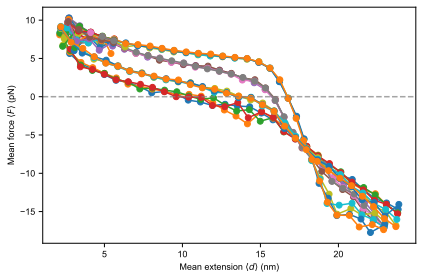

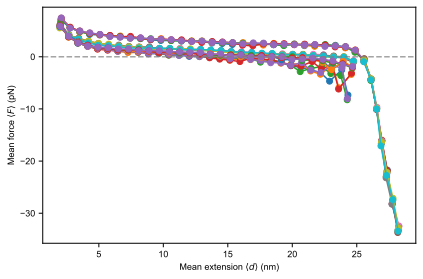

In [41]:
from collections import defaultdict
import numpy as np

# Unit conversion factors
DIST_CONVERSION = 0.8   # to nm
FORCE_CONVERSION = 48.6 # to pN

def plot_force_extension(stats_dict, design_keyword=None, figsize=(6, 4), show_legend=False):
    grouped = defaultdict(list)
    
    for subfolder_name, files_dict in stats_dict.items():
        if design_keyword and design_keyword.lower() not in subfolder_name.lower():
            continue
        
        for (K, r0, seed), stats in files_dict.items():
            grouped[(subfolder_name, K, seed)].append((stats['dist_mean'], stats['F_mean']))

    fig, ax = plt.subplots(figsize=figsize)
    
    for (subfolder_name, K, seed), points in grouped.items():
        points = np.array(sorted(points, key=lambda p: p[0]))
        x = DIST_CONVERSION * points[:, 0]
        y = FORCE_CONVERSION * points[:, 1]
        ax.plot(x, y, marker='o', linewidth=1.5, markersize=6,
                label=f"{subfolder_name}, K={K}, seed={seed}")

    ax.axhline(0, color='gray', linestyle='dashed', alpha=0.7)
    ax.set_xlabel(r"Mean extension $\langle d \rangle$ (nm)")
    ax.set_ylabel(r"Mean force $\langle F \rangle$ (pN)")
    
    if show_legend:
        ax.legend(fontsize=9, bbox_to_anchor=(1.02, 1), loc='upper left')
    
    plt.tight_layout()
    plt.show()

# Reuse exact same plotting code for both push and pull designs
for design in ("push", "pull"):
    plot_force_extension(stats_dict, design_keyword=design, show_legend=False)

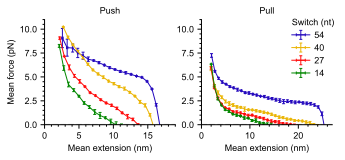

Push - 54: 12.022832 ± 0.105731 kcal/mol
Push - 40: 9.317508 ± 0.035257 kcal/mol
Push - 27: 5.250946 ± 0.038898 kcal/mol
Push - 14: 2.936334 ± 0.050863 kcal/mol
Pull - 54: 10.241933 ± 0.053729 kcal/mol
Pull - 40: 4.460994 ± 0.052449 kcal/mol
Pull - 27: 2.823170 ± 0.039573 kcal/mol
Pull - 14: 2.183241 ± 0.033141 kcal/mol


In [129]:
#### Aggregate means/error bars across seeds and reuse for push/pull
from collections import defaultdict
import numpy as np

AVOGADRO = 6.022e23  # molecules per mole
dict_work_done = {}
dict_work_done_all = defaultdict(list)  # Track all work done values per (design, label)

ROD_CONFIGS = [
    ('full', '54', "#2308bd"),
    ('3qrt', '40', "#eab506"),
    ('half', '27', "#ff0a0a"),
    ('1qrt', '14', "#028700FF"),
]

def aggregate_by_rod(stats_dict, rod_configs, design_keyword=None):
    grouped = {rod: defaultdict(list) for rod, _, _ in rod_configs}
    
    for subfolder_name, files_dict in stats_dict.items():
        subfolder_lower = subfolder_name.lower()
        if design_keyword and design_keyword.lower() not in subfolder_lower:
            continue
        
        for rod_substr, _, _ in rod_configs:
            if rod_substr in subfolder_lower:
                for (K, r0, seed), stats in files_dict.items():
                    grouped[rod_substr][(K, r0)].append(stats)
                break

    aggregated = {}
    for rod_substr, grouped_by_kr0 in grouped.items():
        rod_points = []
        for (K, r0), entries in grouped_by_kr0.items():
            dist_vals = np.array([e['dist_mean'] for e in entries])
            force_vals = np.array([e['F_mean'] for e in entries])
            ddof = 1 if len(entries) > 1 else 0
            rod_points.append({
                'K': K,
                'r0': r0,
                'dist_mean': dist_vals.mean(),
                'F_mean': force_vals.mean(),
                'dist_err': dist_vals.std(ddof=ddof),
                'F_err': force_vals.std(ddof=ddof),
                'n': len(entries),
            })
        aggregated[rod_substr] = sorted(rod_points, key=lambda x: x['dist_mean'])

    return aggregated

def plot_aggregated_rod_curves(
    stats_dict, rod_configs, design_keyword=None, figsize=(5, 4),
    xlim=(0, 18), ylim=(0, 11)
 ):
    aggregated_data = aggregate_by_rod(stats_dict, rod_configs, design_keyword=design_keyword)
    fig, ax = plt.subplots(figsize=figsize)

    all_x = [
        DIST_CONVERSION * point['dist_mean']
        for rod_points in aggregated_data.values()
        for point in rod_points
    ]
    if all_x:
        xmin = xlim[0] if xlim[0] is not None else min(all_x)
        xmax = xlim[1] if xlim[1] is not None else max(all_x)

    area_by_rod = {}
    for rod_substr, label, color in rod_configs:
        points = aggregated_data[rod_substr]
        if not points:
            continue

        x = np.array([DIST_CONVERSION * p['dist_mean'] for p in points])
        y = np.array([FORCE_CONVERSION * p['F_mean'] for p in points])
        xerr = np.array([DIST_CONVERSION * p['dist_err'] for p in points])
        yerr = np.array([FORCE_CONVERSION * p['F_err'] for p in points])

        ax.errorbar(
            x, y, xerr=xerr, yerr=yerr, linestyle='-',
            linewidth=1, capsize=3, label=label, color=color
        )

        area_by_rod[label] = np.trapezoid(np.maximum(y, 0.0), x) if len(x) > 1 else float('nan')

    ax.set_xlabel(r"Mean extension (nm)")
    ax.set_ylabel(r"Mean force (pN)")
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.legend(frameon=False)
    ax.minorticks_on()
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.tight_layout()
    plt.show()

    plt.tight_layout()
    plt.show()

    for label, area in area_by_rod.items():
        kcalpermol = area * 1e-21 * AVOGADRO / 4184
        dict_work_done[(design_keyword, label)] = kcalpermol
        print(f"{label}: area under positive mean trajectory = {area:.4f} pN*nm (10^-21 J) -> {kcalpermol:.6f} kcal/mol")

    return aggregated_data, area_by_rod

def calculate_work_error_from_mean_curve(points):
    """
    Calculate work done and its standard deviation using error propagation from the mean curve.
    
    This method:
    1. Uses the mean force curve with its error bars
    2. Propagates uncertainties through the trapezoid integration
    3. For each segment, error in area = (Δdx) * (Δy_i + Δy_{i+1})/2
    4. Total error = sqrt(sum of squared segment errors)
    
    Args:
        points: list of point dictionaries containing F_mean, F_err, dist_mean, dist_err
    
    Returns:
        work_mean (float): mean work done in kcal/mol
        work_std (float): standard deviation in kcal/mol
    """
    if not points:
        return np.nan, np.nan
    
    x = np.array([DIST_CONVERSION * p['dist_mean'] for p in points])
    y = np.array([FORCE_CONVERSION * p['F_mean'] for p in points])
    dy = np.array([FORCE_CONVERSION * p['F_err'] for p in points])
    
    y_positive = np.maximum(y, 0.0)
    work_pn_nm = np.trapezoid(y_positive, x) if len(x) > 1 else 0.0
    
    segment_errors = []
    for i in range(len(x) - 1):
        dx = x[i + 1] - x[i]
        dy_i = dy[i] if y[i] > 0 else 0
        dy_i1 = dy[i + 1] if y[i + 1] > 0 else 0
        error_segment = dx * np.sqrt((dy_i / 2) ** 2 + (dy_i1 / 2) ** 2)
        segment_errors.append(error_segment)
    
    total_error_pn_nm = np.sqrt(np.sum(np.array(segment_errors) ** 2)) if segment_errors else 0.0
    work_mean = work_pn_nm * 1e-21 * AVOGADRO / 4184
    work_std = total_error_pn_nm * 1e-21 * AVOGADRO / 4184
    
    return work_mean, work_std

# Per-design axis controls
DESIGNS = ("push", "pull")
XLIMS = ((0, 19), (0, 27))
YLIMS = ((0, 11), (0, 11))
DESIGNS_INTERCEPT = ("push", "pull")
XLIMS_INTERCEPT = ((0, 19), (0, 27))
YLIMS_INTERCEPT = ((0, 11), (0, 11))

# Keep the same figure size; arrange the subplot block on the left and the legend on the right.
fig, axes = plt.subplots(1, 2, figsize=(4.5, 1.9), sharey=False, sharex=False)

LAYOUT_LEFT = 0.10
LAYOUT_RIGHT = 0.99
LAYOUT_TOP = 1.00
LAYOUT_BOTTOM = 0.23
LAYOUT_WSPACE = 0.20

LEGEND_X = 0.84
LEGEND_Y = 0.79
LEGEND_COL_SPACING = 0.1
LEGEND_HANDLE_TEXT_PAD = 0.5

handles_list = []
labels_list = []

for idx, (design, xlim, ylim) in enumerate(zip(DESIGNS, XLIMS, YLIMS)):
    ax = axes[idx]
    aggregated_data = aggregate_by_rod(stats_dict, ROD_CONFIGS, design_keyword=design)
    
    all_x = [
        DIST_CONVERSION * point['dist_mean']
        for rod_points in aggregated_data.values()
        for point in rod_points
    ]
    if all_x:
        xmin = xlim[0] if xlim[0] is not None else min(all_x)
        xmax = xlim[1] if xlim[1] is not None else max(all_x)
        ax.hlines(0, xmin=xmin, xmax=xmax, colors='gray', linestyles='dashed', alpha=0.7)

    for rod_substr, label, color in ROD_CONFIGS:
        points = aggregated_data[rod_substr]
        if not points:
            continue

        x = np.array([DIST_CONVERSION * p['dist_mean'] for p in points])
        y = np.array([FORCE_CONVERSION * p['F_mean'] for p in points])
        xerr = np.array([DIST_CONVERSION * p['dist_err'] for p in points])
        yerr = np.array([FORCE_CONVERSION * p['F_err'] for p in points])

        line = ax.errorbar(
            x, y, xerr=xerr, yerr=yerr, linestyle='-',
            linewidth=1, capsize=1.5, label=label, color=color
        )
        
        if idx == 0:
            handles_list.append(line)
            labels_list.append(label.replace(' switch', ''))

    ax.set_xlabel(r"Mean extension (nm)")
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.minorticks_on()
    if ax == axes[0]:
        ax.set_ylabel(r"Mean force (pN)")
    elif ax == axes[1]:
        ax.set_ylabel("")
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_title(design.capitalize(), fontsize=9)

fig.legend(
    handles_list, labels_list,
    loc='center left',
    bbox_to_anchor=(LEGEND_X, LEGEND_Y),
    bbox_transform=fig.transFigure,
    ncol=1,
    frameon=False,
    title='Switch (nt)',
    columnspacing=LEGEND_COL_SPACING,
    handletextpad=LEGEND_HANDLE_TEXT_PAD,
    alignment='left'
)
fig.subplots_adjust(
    left=LAYOUT_LEFT,
    right=LAYOUT_RIGHT,
    top=LAYOUT_TOP,
    bottom=LAYOUT_BOTTOM,
    wspace=LAYOUT_WSPACE,
)
plt.show()

# Calculate work done using error propagation from the mean curve
for design in DESIGNS:
    aggregated_data = aggregate_by_rod(stats_dict, ROD_CONFIGS, design_keyword=design)
    
    for rod_substr, label, color in ROD_CONFIGS:
        points = aggregated_data[rod_substr]
        if not points:
            continue
        
        work_mean, work_std = calculate_work_error_from_mean_curve(points)
        dict_work_done[(design, label)] = work_mean
        dict_work_done_all[(design, label)] = [work_mean, work_std]
        print(f"{design.capitalize()} - {label}: {work_mean:.6f} ± {work_std:.6f} kcal/mol")

push intercept points: [(14, 10.347120543242001, '14'), (27, 13.58732845729456, '27'), (40, 15.756987747766647, '40'), (54, 16.73111666005712, '54')]
pull intercept points: [(14, 13.727812432923155, '14'), (27, 18.547929564221572, '27'), (40, 23.31945702414239, '40'), (54, 25.300003086225473, '54')]


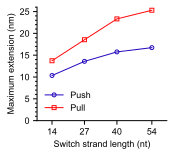

In [141]:
#### MAXIMUM EXTENSION VS ROD LENGTH (push/pull on same axes, no function wrappers)
import re
import numpy as np
import matplotlib.pyplot as plt

DESIGNS_INTERCEPT = ("push", "pull")
DESIGN_STYLE = {
    "push": {"color": "#2308bd", "marker": "o", "label": "Push"},
    "pull": {"color": "#ff0a0a", "marker": "s", "label": "Pull"},
}

intercepts_by_design = {}

for design in DESIGNS_INTERCEPT:
    aggregated_data = aggregate_by_rod(stats_dict, ROD_CONFIGS, design_keyword=design)
    points = []

    for rod_substr, label, _ in ROD_CONFIGS:
        agg = aggregated_data.get(rod_substr, [])
        if not agg:
            continue

        x_vals = np.array([DIST_CONVERSION * d['dist_mean'] for d in agg])
        y_vals = np.array([FORCE_CONVERSION * d['F_mean'] for d in agg])

        order = np.argsort(x_vals)
        x_vals = x_vals[order]
        y_vals = y_vals[order]

        x0 = None
        for i in range(len(y_vals) - 1):
            y0, y1 = y_vals[i], y_vals[i + 1]
            x_start, x_end = x_vals[i], x_vals[i + 1]

            if y0 == 0:
                x0 = float(x_start)
                break
            if y1 == 0:
                x0 = float(x_end)
                break
            if y0 * y1 < 0:
                x0 = float(x_start + (0 - y0) * (x_end - x_start) / (y1 - y0))
                break

        if x0 is None:
            continue

        match = re.search(r"(\d+)", label)
        if not match:
            continue

        rod_length = int(match.group(1))
        points.append((rod_length, x0, label))

    points.sort(key=lambda t: t[0])
    intercepts_by_design[design] = points
    print(f"{design} intercept points: {points}")

fig, ax = plt.subplots(figsize=(2.5, 2.25))

for design in DESIGNS_INTERCEPT:
    points = intercepts_by_design.get(design, [])
    if not points:
        continue

    rod_lengths, x_intercepts, _ = zip(*points)
    style = DESIGN_STYLE[design]
    ax.plot(
        rod_lengths, x_intercepts,
        marker=style["marker"], markersize=4,
        markerfacecolor='none', markeredgewidth=1,
        color=style["color"], linewidth=1,
        label=style["label"]
    )

x_vals = [54, 40, 27, 14]
ax.set_xlabel("Switch strand length (nt)")
ax.set_ylabel("Maximum extension (nm)")
ax.set_xlim(8, 60)
ax.set_ylim(0, 26)
ax.set_xticks(x_vals)
ax.yaxis.minorticks_on()
ax.tick_params(which='minor', axis='y', direction='out', color='black')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

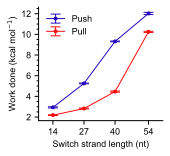

In [140]:
#### PLOTS OF WORK DONE VS ROD LENGTH
x_vals = [54, 40, 27, 14]

# Extract work done and error bars for push (using error propagation from mean curve)
y_vals_push = [dict_work_done[(key)] for key in [('push', '54'),
                                                 ('push', '40'),
                                                 ('push', '27'),
                                                 ('push', '14')]]
err_vals_push = [dict_work_done_all[(key)][1] for key in [('push', '54'),
                                                           ('push', '40'),
                                                           ('push', '27'),
                                                           ('push', '14')]]

# Extract work done and error bars for pull (using error propagation from mean curve)
y_vals_pull = [dict_work_done[(key)] for key in [('pull', '54'),
                                                 ('pull', '40'),
                                                 ('pull', '27'),
                                                 ('pull', '14')]]
err_vals_pull = [dict_work_done_all[(key)][1] for key in [('pull', '54'),
                                                           ('pull', '40'),
                                                           ('pull', '27'),
                                                           ('pull', '14')]]

fig, ax = plt.subplots(figsize=(2.5, 2.25))
# first traj
ax.errorbar(x_vals, y_vals_push, yerr=err_vals_push, marker='o', markersize=3,
            color="#2308bd", linewidth=1, capsize=5, label='Push')
# second traj
ax.errorbar(x_vals, y_vals_pull, yerr=err_vals_pull, marker='o', markersize=3,
            color="#ff0a0a", linewidth=1, capsize=5, label='Pull')

ax.set_xlabel("Switch strand length (nt)")
ax.set_ylabel("Work done (kcal mol$^{-1}$)")
ax.yaxis.minorticks_on()
ax.tick_params(which='minor', axis='y', direction='out', color='black')
ax.set_xticks(x_vals)
ax.set_xlim(8, 60)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()
